# UMAP Visualization of Latent Intentions

Load a rollout dataset H5 file (from `collect_rollout_dataset` or `collect_rollout_dataset_distill`),
perform 3D UMAP on a chosen latent dataset, and visualize with an interactive Plotly scatter.

## Setup

In [1]:
import h5py
import numpy as np
import plotly.graph_objects as go
from umap import UMAP

/home/mila/a/aidan.sirbu/SCAMPER/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration

In [2]:
# ============ CONFIGURATION ============
# Path to rollout dataset H5 file (from collect_rollout_dataset or collect_rollout_dataset_distill)
DATASET_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"  # Update this path

# Name of the latent dataset to visualize.
# Common options:
#   collect_rollout_dataset:         encoder_decoder_latents, prior_deterministic_latents,
#                                    prior_predicted_logvar_latents, prior_logvar_-4_latents, ...
#   collect_rollout_dataset_distill: student_encoder_decoder_latents, prior_deterministic_latents, ...
LATENT_DATASET = "encoder_decoder_latents"

# UMAP parameters
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
UMAP_METRIC = "euclidean"
UMAP_RANDOM_STATE = 42

# Subsampling: set to None to use all points, or an integer to randomly sample that many points.
# Recommended for large datasets (num_clips * num_steps can be >100k).
MAX_POINTS = 50_000

# Coloring: "clip" colors by clip index, "timestep" colors by timestep within each clip
COLOR_BY = "clip"

## Load Latents

In [3]:
with h5py.File(DATASET_PATH, "r") as f:
    print("Datasets in file:")
    for key in sorted(f.keys()):
        print(f"  {key}: {f[key].shape}")
    print()
    print("Attributes:")
    for key, value in f.attrs.items():
        print(f"  {key}: {value}")

    assert LATENT_DATASET in f, (
        f"Dataset '{LATENT_DATASET}' not found. "
        f"Available: {sorted(f.keys())}"
    )
    latents = f[LATENT_DATASET][:]  # (num_clips, num_steps, intention_size)

num_clips, num_steps, intention_size = latents.shape
print(f"\nLoaded '{LATENT_DATASET}': {latents.shape}")
print(f"  num_clips={num_clips}, num_steps={num_steps}, intention_size={intention_size}")

Datasets in file:
  encoder_decoder_latents: (842, 490, 16)
  encoder_decoder_qpos: (842, 490, 74)
  original_qpos: (842, 250, 74)
  prior_deterministic_latents: (842, 490, 16)
  prior_deterministic_qpos: (842, 490, 74)
  prior_logvar_-0.5_latents: (842, 490, 16)
  prior_logvar_-0.5_qpos: (842, 490, 74)
  prior_logvar_-1_latents: (842, 490, 16)
  prior_logvar_-1_qpos: (842, 490, 74)
  prior_logvar_-2_latents: (842, 490, 16)
  prior_logvar_-2_qpos: (842, 490, 74)
  prior_logvar_-3_latents: (842, 490, 16)
  prior_logvar_-3_qpos: (842, 490, 74)
  prior_logvar_-4_latents: (842, 490, 16)
  prior_logvar_-4_qpos: (842, 490, 74)
  prior_logvar_0_latents: (842, 490, 16)
  prior_logvar_0_qpos: (842, 490, 74)
  prior_predicted_logvar_latents: (842, 490, 16)
  prior_predicted_logvar_qpos: (842, 490, 74)

Attributes:
  checkpoint_path: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/golden_rodent_prior_jax
  intention_size: 16
  logvars: [-4.  -3.  -2.  -1.  -0.5  0. ]
  num_clips: 842
 

## Prepare Data for UMAP

In [10]:
# Flatten to (num_clips * num_steps, intention_size)
flat_latents = latents.reshape(-1, intention_size)

# Build metadata arrays for coloring
clip_ids = np.repeat(np.arange(num_clips), num_steps)
timesteps = np.tile(np.arange(num_steps), num_clips)

# Skip t=0 where latents are always zero (no policy call at start)
nonzero_mask = timesteps > 0
flat_latents = flat_latents[nonzero_mask]
clip_ids = clip_ids[nonzero_mask]
timesteps = timesteps[nonzero_mask]

print(f"Points after removing t=0: {len(flat_latents)}")

# Subsample if needed
if MAX_POINTS is not None and len(flat_latents) > MAX_POINTS:
    rng = np.random.default_rng(UMAP_RANDOM_STATE)
    indices = rng.choice(len(flat_latents), size=MAX_POINTS, replace=False)
    indices.sort()
    flat_latents = flat_latents[indices]
    clip_ids = clip_ids[indices]
    timesteps = timesteps[indices]
    print(f"Subsampled to {MAX_POINTS} points")

print(f"Final shape for UMAP: {flat_latents.shape}")

Points after removing t=0: 411738
Subsampled to 50000 points
Final shape for UMAP: (50000, 16)


## Run UMAP

In [11]:
reducer = UMAP(
    n_components=3,
    n_neighbors=UMAP_N_NEIGHBORS,
    min_dist=UMAP_MIN_DIST,
    metric=UMAP_METRIC,
    random_state=UMAP_RANDOM_STATE,
)

embedding = reducer.fit_transform(flat_latents)
print(f"UMAP embedding shape: {embedding.shape}")

/home/mila/a/aidan.sirbu/SCAMPER/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding shape: (50000, 3)


## Interactive 3D Visualization

In [7]:
if COLOR_BY == "clip":
    color_values = clip_ids
    colorbar_title = "Clip Index"
elif COLOR_BY == "timestep":
    color_values = timesteps
    colorbar_title = "Timestep"
else:
    raise ValueError(f"Unknown COLOR_BY='{COLOR_BY}'. Use 'clip' or 'timestep'.")

fig = go.Figure(
    data=[
        go.Scatter3d(
            x=embedding[:, 0],
            y=embedding[:, 1],
            z=embedding[:, 2],
            mode="markers",
            marker=dict(
                size=2,
                color=color_values,
                colorscale="Viridis",
                colorbar=dict(title=colorbar_title),
                opacity=0.7,
            ),
            hovertemplate=(
                "UMAP1: %{x:.2f}<br>"
                "UMAP2: %{y:.2f}<br>"
                "UMAP3: %{z:.2f}<br>"
                "Clip: %{customdata[0]}<br>"
                "Timestep: %{customdata[1]}"
                "<extra></extra>"
            ),
            customdata=np.stack([clip_ids, timesteps], axis=-1),
        )
    ]
)

fig.update_layout(
    title=f"3D UMAP — {LATENT_DATASET} (colored by {COLOR_BY})",
    scene=dict(
        xaxis_title="UMAP 1",
        yaxis_title="UMAP 2",
        zaxis_title="UMAP 3",
    ),
    width=900,
    height=700,
    margin=dict(l=0, r=0, b=0, t=40),
)

fig.show()

## L2 Norm Histogram

Compare the distribution of latent vector norms across two datasets.
Latents regularized toward N(0,1) should concentrate around `sqrt(d)`, while
latents regularized toward a conditional prior may show a different spread.

In [4]:
# ============ L2 NORM CONFIGURATION ============
# Paths to two H5 files to compare (set both, or set the second to None to plot just one)
L2_DATASET_PATH_A = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"  # Imitation -> Prior (N(0,1) regularized)
L2_DATASET_PATH_B = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_matchKL_clamp_49.h5"  # Imitation MLP -> Distill (conditional prior regularized)

# Which latent dataset to use from each file
L2_LATENT_DATASET_A = "encoder_decoder_latents"
L2_LATENT_DATASET_B = "student_encoder_decoder_latents"

# Labels for the legend
L2_LABEL_A = "SCAMPER"
L2_LABEL_B = "PULSE"

In [5]:
import plotly.figure_factory as ff


def load_l2_norms(path, dataset_name):
    """Load latents from an H5 file and return per-timestep L2 norms."""
    with h5py.File(path, "r") as f:
        latents = f[dataset_name][:]  # (num_clips, num_steps, intention_size)
    # Skip t=0 (always zero)
    latents = latents[:, 1:, :]
    # Flatten to (N, intention_size) then compute norms
    flat = latents.reshape(-1, latents.shape[-1])
    return np.linalg.norm(flat, axis=-1)


norms_a = load_l2_norms(L2_DATASET_PATH_A, L2_LATENT_DATASET_A)
hist_data = [norms_a]
group_labels = [L2_LABEL_A]

if L2_DATASET_PATH_B is not None:
    norms_b = load_l2_norms(L2_DATASET_PATH_B, L2_LATENT_DATASET_B)
    hist_data.append(norms_b)
    group_labels.append(L2_LABEL_B)

# Subsample for plotting speed (KDE on 400k+ points is slow)
rng = np.random.default_rng(42)
hist_data = [
    d[rng.choice(len(d), size=min(50_000, len(d)), replace=False)] for d in hist_data
]

fig = ff.create_distplot(hist_data, group_labels, bin_size=0.1, show_rug=False)
fig.update_layout(
    title="L2 Norm Distribution of Latent Vectors",
    xaxis_title="||z||₂",
    yaxis_title="Density",
    width=800,
    height=500,
)

# Add vertical line at sqrt(d) for N(0,1) reference
d = norms_a.size and latents.shape[-1] if "latents" in dir() else 16  # fallback
with h5py.File(L2_DATASET_PATH_A, "r") as f:
    d = f[L2_LATENT_DATASET_A].shape[-1]
fig.add_vline(
    x=np.sqrt(d),
    line_dash="dash",
    line_color="gray",
    annotation_text=f"√d = {np.sqrt(d):.1f}",
    annotation_position="top right",
)

fig.show()

## Per-Dimension Marginal KDEs

Plot the distribution of each latent dimension for both methods overlaid.
N(0,1)-regularized dimensions should each look like a standard normal,
while conditional-prior-regularized dimensions may show shifted means or multimodality.

In [6]:
# ============ PER-DIMENSION KDE CONFIGURATION ============
# Reuses L2_DATASET_PATH_A/B, L2_LATENT_DATASET_A/B, L2_LABEL_A/B from above.
# Set how many latent dimensions to show per row in the subplot grid.
KDE_COLS = 4

In [7]:
from plotly.subplots import make_subplots
from scipy.stats import gaussian_kde


def load_flat_latents(path, dataset_name, max_points=50_000, seed=42):
    """Load latents, skip t=0, flatten, and subsample."""
    with h5py.File(path, "r") as f:
        lat = f[dataset_name][:]  # (num_clips, num_steps, d)
    lat = lat[:, 1:, :]  # skip t=0
    flat = lat.reshape(-1, lat.shape[-1])
    if len(flat) > max_points:
        rng = np.random.default_rng(seed)
        flat = flat[rng.choice(len(flat), size=max_points, replace=False)]
    return flat


flat_a = load_flat_latents(L2_DATASET_PATH_A, L2_LATENT_DATASET_A)
flat_b = (
    load_flat_latents(L2_DATASET_PATH_B, L2_LATENT_DATASET_B)
    if L2_DATASET_PATH_B is not None
    else None
)

d = flat_a.shape[1]
rows = int(np.ceil(d / KDE_COLS))

fig = make_subplots(
    rows=rows,
    cols=KDE_COLS,
    subplot_titles=[f"z[{i}]" for i in range(d)],
    horizontal_spacing=0.05,
    vertical_spacing=0.08,
)

# Shared x grid for KDE evaluation
x_grid = np.linspace(-6, 6, 300)

# Reference N(0,1) pdf
normal_pdf = np.exp(-0.5 * x_grid**2) / np.sqrt(2 * np.pi)

for i in range(d):
    row = i // KDE_COLS + 1
    col = i % KDE_COLS + 1
    show_legend = i == 0

    # N(0,1) reference
    fig.add_trace(
        go.Scatter(
            x=x_grid,
            y=normal_pdf,
            mode="lines",
            line=dict(color="gray", dash="dash", width=1),
            name="N(0,1)",
            legendgroup="ref",
            showlegend=show_legend,
        ),
        row=row,
        col=col,
    )

    # Dataset A
    kde_a = gaussian_kde(flat_a[:, i])
    fig.add_trace(
        go.Scatter(
            x=x_grid,
            y=kde_a(x_grid),
            mode="lines",
            line=dict(color="#636EFA", width=1.5),
            name=L2_LABEL_A,
            legendgroup="a",
            showlegend=show_legend,
        ),
        row=row,
        col=col,
    )

    # Dataset B
    if flat_b is not None:
        kde_b = gaussian_kde(flat_b[:, i])
        fig.add_trace(
            go.Scatter(
                x=x_grid,
                y=kde_b(x_grid),
                mode="lines",
                line=dict(color="#EF553B", width=1.5),
                name=L2_LABEL_B,
                legendgroup="b",
                showlegend=show_legend,
            ),
            row=row,
            col=col,
        )

fig.update_layout(
    title="Per-Dimension Latent Marginals",
    height=250 * rows,
    width=250 * KDE_COLS,
    showlegend=True,
)
fig.show()

## PCA Comparison

PCA preserves global variance structure (unlike UMAP). Two views:
1. **Explained variance ratio** — N(0,1)-regularized latents should spread variance more uniformly across components, while conditional-prior latents should concentrate variance in fewer top PCs.
2. **2D scatter of PC1 vs PC2** — shows the actual shape of the distribution in the highest-variance plane.

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/pca_explained_variance.[pdf|svg|png]


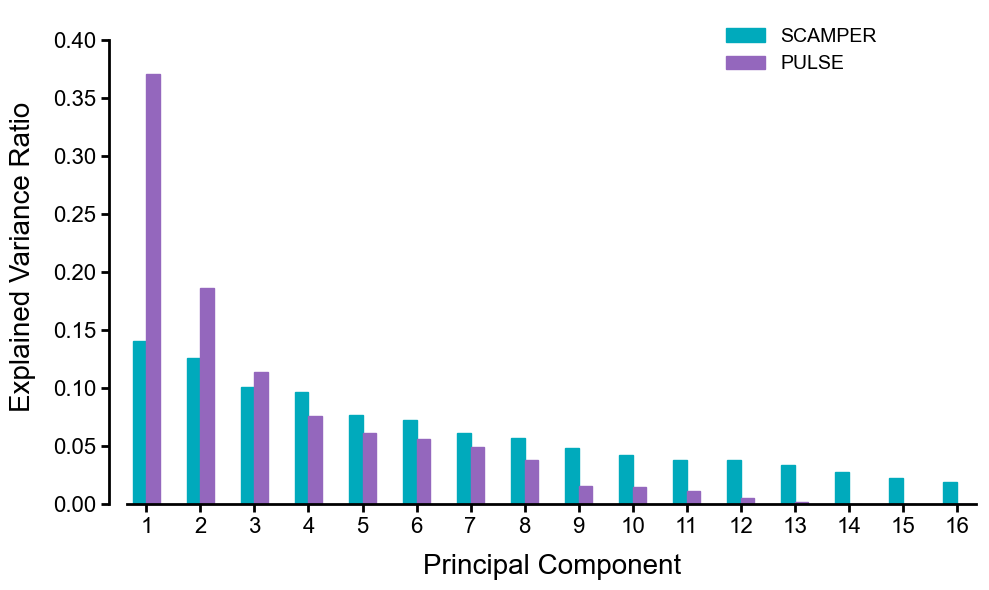

In [25]:
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

matplotlib.rcParams["font.family"] = "Arial"

# Reuse flat_a / flat_b from the per-dimension KDE section above.
# Fit PCA on each dataset independently so explained variance is comparable.
pca_a = PCA().fit(flat_a)
pca_b = PCA().fit(flat_b) if flat_b is not None else None

# --- Explained variance ratio bar chart ---
scamper_color = (0 / 255, 170 / 255, 188 / 255)
pulse_color = (148 / 255, 103 / 255, 189 / 255)

d = len(pca_a.explained_variance_ratio_)
x = np.arange(1, d + 1) * 1.4
bar_width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# SCAMPER bars (left)
ax.bar(
    x - bar_width / 2,
    pca_a.explained_variance_ratio_,
    bar_width,
    color=scamper_color,
    edgecolor=scamper_color,
    label=L2_LABEL_A,
)

# PULSE bars (right)
if pca_b is not None:
    ax.bar(
        x + bar_width / 2,
        pca_b.explained_variance_ratio_,
        bar_width,
        color=pulse_color,
        edgecolor=pulse_color,
        label=L2_LABEL_B,
    )

ax.set_xticks(x)
ax.set_xticklabels([str(i) for i in range(1, d + 1)])
ax.set_xlim(x[0] - 0.6, x[-1] + 0.6)

y_max = max(pca_a.explained_variance_ratio_.max(),
            pca_b.explained_variance_ratio_.max() if pca_b is not None else 0)
ax.set_ylim(0, y_max * 1.15)

ax.set_ylabel("Explained Variance Ratio", fontsize=20, labelpad=12)
ax.set_xlabel("Principal Component", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False, loc="upper right", bbox_to_anchor=(0.9, 1.0))

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])
ax.spines["bottom"].set_bounds(x[0] - 0.5, x[-1] + 0.5)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
save_dir.mkdir(parents=True, exist_ok=True)
save_name = "pca_explained_variance"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(save_dir / f"{save_name}.{ext}", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()


In [9]:
# --- PC1 vs PC2 scatter (subsample for speed) ---
PCA_SCATTER_POINTS = 10_000
rng = np.random.default_rng(42)

proj_a = pca_a.transform(flat_a)
idx_a = rng.choice(len(proj_a), size=min(PCA_SCATTER_POINTS, len(proj_a)), replace=False)

fig = go.Figure()
fig.add_trace(
    go.Scattergl(
        x=proj_a[idx_a, 0],
        y=proj_a[idx_a, 1],
        mode="markers",
        marker=dict(size=2, color="#636EFA", opacity=0.4),
        name=L2_LABEL_A,
    )
)

if flat_b is not None:
    proj_b = pca_b.transform(flat_b)
    idx_b = rng.choice(len(proj_b), size=min(PCA_SCATTER_POINTS, len(proj_b)), replace=False)
    fig.add_trace(
        go.Scattergl(
            x=proj_b[idx_b, 0],
            y=proj_b[idx_b, 1],
            mode="markers",
            marker=dict(size=2, color="#EF553B", opacity=0.4),
            name=L2_LABEL_B,
        )
    )

fig.update_layout(
    title="PCA — PC1 vs PC2",
    xaxis_title=f"PC1 ({pca_a.explained_variance_ratio_[0]:.1%} var)",
    yaxis_title=f"PC2 ({pca_a.explained_variance_ratio_[1]:.1%} var)",
    width=700,
    height=700,
    yaxis_scaleanchor="x",
)
fig.show()

## Participation Ratio

Quantifies the effective dimensionality of the latent space.

$$PR = \frac{\left(\sum_i \lambda_i\right)^2}{\sum_i \lambda_i^2}$$

where $\lambda_i$ are the eigenvalues of the covariance matrix (i.e. PCA explained variances).
- **PR = d** (here 16): variance is spread uniformly — expected for N(0,1) regularization.
- **PR = 1**: all variance in a single direction — maximally concentrated.
- Conditional-prior regularization should yield a lower PR than N(0,1), reflecting more structured/anisotropic latent usage.

In [10]:
def participation_ratio(eigenvalues):
    """Compute participation ratio from eigenvalues."""
    return np.sum(eigenvalues) ** 2 / np.sum(eigenvalues**2)


# Reuse PCA fits from above (pca_a, pca_b already fitted on flat_a, flat_b)
eigenvalues_a = pca_a.explained_variance_
pr_a = participation_ratio(eigenvalues_a)

print(f"{'Method':<35} {'PR':>8}  {'PR / d':>8}")
print("-" * 55)
print(f"{L2_LABEL_A:<35} {pr_a:>8.2f}  {pr_a / len(eigenvalues_a):>8.2f}")

if pca_b is not None:
    eigenvalues_b = pca_b.explained_variance_
    pr_b = participation_ratio(eigenvalues_b)
    print(f"{L2_LABEL_B:<35} {pr_b:>8.2f}  {pr_b / len(eigenvalues_b):>8.2f}")

print(f"\n(d = {len(eigenvalues_a)}, PR/d = 1.0 means perfectly isotropic)")

Method                                    PR    PR / d
-------------------------------------------------------
SCAMPER                                12.06      0.75
PULSE                                   4.95      0.31

(d = 16, PR/d = 1.0 means perfectly isotropic)


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/pca_explained_variance_with_pr.[pdf|svg|png]


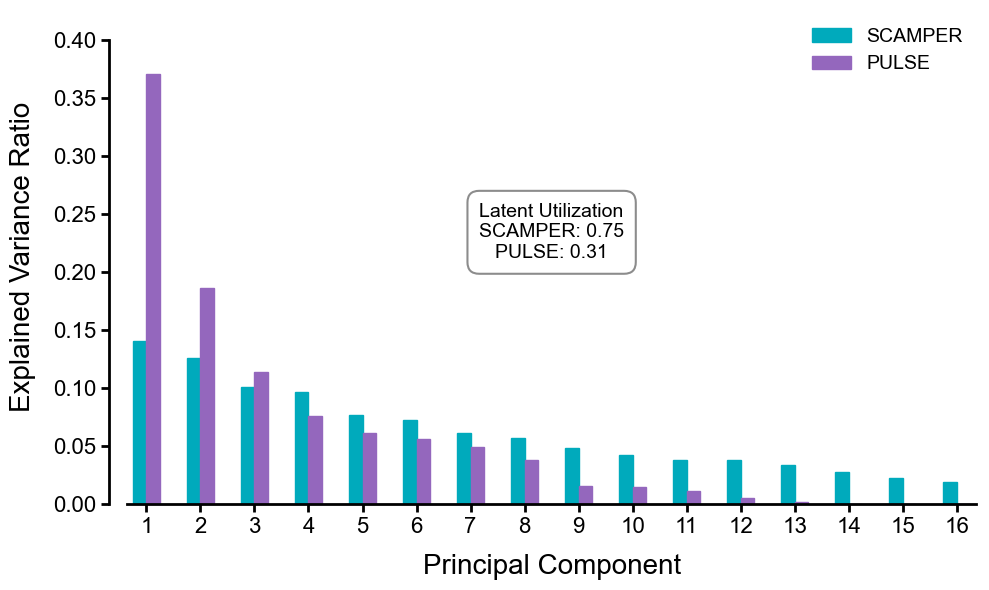

In [20]:
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.rcParams["font.family"] = "Arial"

scamper_color = (0 / 255, 170 / 255, 188 / 255)
pulse_color = (148 / 255, 103 / 255, 189 / 255)

d = len(pca_a.explained_variance_ratio_)
x = np.arange(1, d + 1) * 1.4
bar_width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# SCAMPER bars (left)
ax.bar(
    x - bar_width / 2,
    pca_a.explained_variance_ratio_,
    bar_width,
    color=scamper_color,
    edgecolor=scamper_color,
    label=L2_LABEL_A,
)

# PULSE bars (right)
if pca_b is not None:
    ax.bar(
        x + bar_width / 2,
        pca_b.explained_variance_ratio_,
        bar_width,
        color=pulse_color,
        edgecolor=pulse_color,
        label=L2_LABEL_B,
    )

ax.set_xticks(x)
ax.set_xticklabels([str(i) for i in range(1, d + 1)])
ax.set_xlim(x[0] - 0.6, x[-1] + 0.6)

y_max = max(pca_a.explained_variance_ratio_.max(),
            pca_b.explained_variance_ratio_.max() if pca_b is not None else 0)
ax.set_ylim(0, y_max * 1.15)

ax.set_ylabel("Explained Variance Ratio", fontsize=20, labelpad=12)
ax.set_xlabel("Principal Component", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False, loc="upper right")

# Add latent utilization box
box_text = "Latent Utilization"
box_text += f"\n{L2_LABEL_A}: {pr_a / d:.2f}"
if pca_b is not None:
    box_text += f"\n{L2_LABEL_B}: {pr_b / d:.2f}"
ax.text(
    0.5, 0.55, box_text,
    transform=ax.transAxes, ha="center", va="center",
    fontsize=14,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="gray",
        linewidth=1.5,
        alpha=0.9,
    ),
)

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])
ax.spines["bottom"].set_bounds(x[0] - 0.5, x[-1] + 0.5)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
save_dir.mkdir(parents=True, exist_ok=True)
save_name = "pca_explained_variance_with_pr"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(save_dir / f"{save_name}.{ext}", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()
